# 05 · Model Selection and Estimator Validation

**Syllabus:** Unit 3 (Model Validation: AIC, BIC, Mallow's Cp).

**Report items:** *Estimator Validation* (cross-validation and bootstrap: stability and distribution of the estimators).

All work uses the **training period only**. The test period stays untouched for the final evaluation.
Target: **log(PM2.5)**, the remedied model from notebook 04.

## 1. Setup

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import TimeSeriesSplit, KFold
%matplotlib inline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
rng = np.random.default_rng(42)

PREDICTORS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
SEASON = "C(Season, Treatment('Winter'))"
df = pd.read_csv(ROOT / "data" / "processed" / "bengaluru_clean.csv", parse_dates=["Date"]).rename(columns={"PM2.5": "PM25"})
model_df = df.dropna(subset=["PM25"] + PREDICTORS).reset_index(drop=True)
SPLIT_DATE = pd.Timestamp(pd.read_csv(TAB / "train_test_split.csv")["SPLIT_DATE"][0])
train = model_df[model_df["Date"] < SPLIT_DATE].sort_values("Date").reset_index(drop=True)
n = len(train)

# Time-series CV: the first training window must cover a full year so that every season
# (and so every Season dummy) has been seen before predicting the next block.
n_first_year = int((train["Date"] < train["Date"].min() + pd.DateOffset(years=1)).sum())
TEST_SIZE = (n - n_first_year) // 5
TS = TimeSeriesSplit(n_splits=5, test_size=TEST_SIZE)
print("Training rows:", n, "| first CV window:", n - 5 * TEST_SIZE, "rows | each CV test block:", TEST_SIZE, "rows")

Training rows: 1181 | first CV window: 316 rows | each CV test block: 173 rows


# Part A: Model selection with AIC, BIC and Mallow's Cp

**All-subsets regression:** every combination of the 8 pollutants, with and without Season (Season is one block of 3 dummies). That is $2^9 - 1 = 511$ candidate models (the empty model is excluded).

| Criterion | Formula | Prefers |
|---|---|---|
| AIC | $n\ln(SSE/n) + 2p$ | Lowest; mild penalty, so slightly bigger models |
| BIC | $n\ln(SSE/n) + p\ln n$ | Lowest; stronger penalty, so smaller models |
| Mallow's $C_p$ | $SSE_p / MSE_{full} - (n - 2p)$ | Small, and close to $p$ (little bias) |
| Adjusted $R^2$ | $1 - \frac{SSE/(n-p)}{SST/(n-1)}$ | Highest |

Here $p$ is the number of parameters including the intercept, and $MSE_{full}$ comes from the model with all predictors.

In [2]:
def rhs(terms):
    return " + ".join(terms) if terms else "1"

full = smf.ols("np.log(PM25) ~ " + rhs(PREDICTORS + [SEASON]), data=train).fit()
MSE_full = full.mse_resid
SST = full.centered_tss

rows = []
for use_season in (False, True):
    for k in range(0, len(PREDICTORS) + 1):
        for subset in combinations(PREDICTORS, k):
            terms = list(subset) + ([SEASON] if use_season else [])
            if not terms:
                continue
            m = smf.ols("np.log(PM25) ~ " + rhs(terms), data=train).fit()
            p = int(m.df_model) + 1
            sse = m.ssr
            rows.append({
                "predictors": ", ".join(subset) + (" + Season" if use_season else ""),
                "n_pollutants": k, "season": use_season, "p": p,
                "SSE": sse, "AdjR2": m.rsquared_adj,
                "AIC": n * np.log(sse / n) + 2 * p,
                "BIC": n * np.log(sse / n) + p * np.log(n),
                "Cp": sse / MSE_full - (n - 2 * p),
            })
subsets = pd.DataFrame(rows)
subsets.to_csv(TAB / "all_subsets.csv", index=False)
print("Models compared:", len(subsets))

Models compared: 511


## 2. Best model under each criterion

In [3]:
best = pd.DataFrame({
    "Lowest AIC": subsets.loc[subsets.AIC.idxmin()],
    "Lowest BIC": subsets.loc[subsets.BIC.idxmin()],
    "Lowest Cp": subsets.loc[subsets.Cp.idxmin()],
    "Highest Adj R2": subsets.loc[subsets.AdjR2.idxmax()],
}).T[["predictors", "p", "AdjR2", "AIC", "BIC", "Cp"]]
best.to_csv(TAB / "best_subset_by_criterion.csv")
best

,predictors,p,AdjR2,AIC,BIC,Cp
Lowest AIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Lowest BIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Lowest Cp,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Highest Adj R2,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000


## 3. Best model for each size

For each number of parameters, keep the model with the smallest SSE (all criteria agree within one size). This shows how much each extra variable is worth.

In [4]:
by_size = subsets.loc[subsets.groupby("p")["SSE"].idxmin()].sort_values("p")
by_size[["p", "predictors", "AdjR2", "AIC", "BIC", "Cp"]].to_csv(TAB / "best_subset_by_size.csv", index=False)
by_size[["p", "predictors", "AdjR2", "AIC", "BIC", "Cp"]]

,p,predictors,AdjR2,AIC,BIC,Cp
0,2,PM10,0.3521,-2126.6577,-2116.5095,777.4400
10,3,"PM10, NOx",0.4433,-2304.9542,-2289.7319,502.7262
50,4,"PM10, NOx, O3",0.4974,-2424.6501,-2404.3536,340.4543
256,5,PM10 + Season,0.5239,-2487.6329,-2462.2623,261.4284
266,6,"PM10, NOx + Season",0.5739,-2617.6173,-2587.1726,111.9662
306,7,"PM10, NOx, O3 + Season",0.5856,-2649.4542,-2613.9354,77.7859
375,8,"PM10, NOx, NH3, O3 + Season",0.5949,-2675.3201,-2634.7271,50.7588
450,9,"PM10, NOx, NH3, SO2, O3 + Season",0.5993,-2687.3562,-2641.6891,38.3951
486,10,"PM10, NO, NOx, NH3, SO2, O3 + Season",0.6018,-2693.6228,-2642.8816,32.0152
504,11,"PM10, NO, NO2, NOx, NH3, SO2, O3 + Season",0.6070,-2708.2336,-2652.4183,17.3528


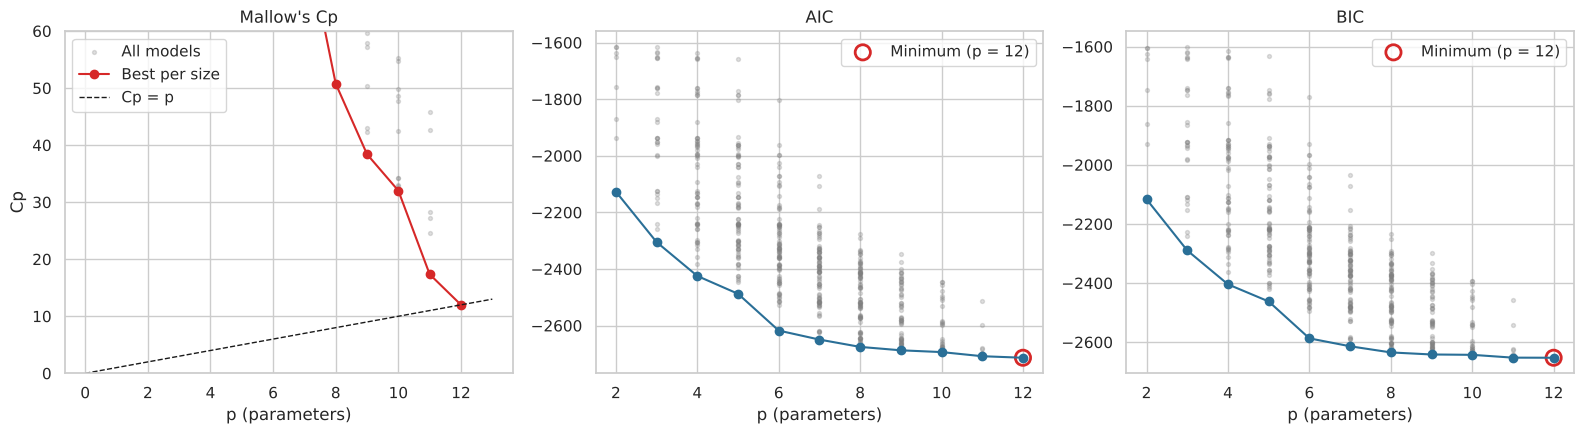

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(subsets.p, subsets.Cp, s=8, alpha=0.25, color="grey", label="All models")
axes[0].plot(by_size.p, by_size.Cp, "o-", color="#d62828", label="Best per size")
lim = [0, subsets.p.max() + 1]
axes[0].plot(lim, lim, "k--", lw=1, label="Cp = p")
axes[0].set_ylim(0, 60); axes[0].set(title="Mallow's Cp", xlabel="p (parameters)", ylabel="Cp"); axes[0].legend()
for ax, crit in zip(axes[1:], ["AIC", "BIC"]):
    ax.scatter(subsets.p, subsets[crit], s=8, alpha=0.25, color="grey")
    ax.plot(by_size.p, by_size[crit], "o-", color="#2a6f97")
    b = subsets.loc[subsets[crit].idxmin()]
    ax.scatter([b.p], [b[crit]], s=120, facecolors="none", edgecolors="#d62828", lw=2, label=f"Minimum (p = {int(b.p)})")
    ax.set(title=crit, xlabel="p (parameters)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "16_model_selection_criteria.png", dpi=150); plt.show()

**Reading the results:**

- A good model has $C_p$ close to the line $C_p = p$; models far above it leave out useful predictors and are biased.
- The full model always has $C_p = p$ exactly (its SSE *is* the reference), so the useful question is whether a **smaller** model also gets close to the line. Here none does: dropping even one variable (CO, the weakest) raises $C_p$ to about 17 with $p = 11$.
- AIC, BIC and $C_p$ all pick the **full model** (8 pollutants + Season). With $n$ = 1181, even BIC's strong penalty ($\ln n \approx 7.1$ per parameter) is outweighed by the fit gained from each predictor.
- The best-per-size table shows the order in which variables matter: **PM10 → NOx → Season → O3 → NH3 → SO2 → NO → NO2 → CO**. Most of the gain comes from the first three (adjusted $R^2$ 0.35 → 0.57).

# Part B: Cross-validation

Candidate models are compared on how well they predict **unseen days**.

- **Time-series CV (main method):** expanding window with 5 folds. The first window covers one full year (so every season is seen); each fold trains on all past days and tests on the next block. This mimics real forecasting, because the model never sees the future.
- **Random 5-fold CV (for contrast):** shuffles days, so the model trains on days right next to the test days. With autocorrelated data this can leak information and look too optimistic.

Errors are measured on the original µg/m³ scale. Log models are back-transformed with the smearing factor estimated inside each training fold.

In [6]:
candidates = {
    "SLR: PM10": ("PM25", ["PM10"]),
    "MLR 1: pollutants": ("PM25", PREDICTORS),
    "MLR 2: + season": ("PM25", PREDICTORS + [SEASON]),
    "log MLR 1": ("log", PREDICTORS),
    "log MLR 2": ("log", PREDICTORS + [SEASON]),
    "log MLR 2 without CO": ("log", [c for c in PREDICTORS if c != "CO"] + [SEASON]),
}

def fit_predict(target, terms, tr, te):
    if target == "log":
        m = smf.ols("np.log(PM25) ~ " + rhs(terms), data=tr).fit()
        return np.exp(m.predict(te)) * np.mean(np.exp(m.resid))
    m = smf.ols("PM25 ~ " + rhs(terms), data=tr).fit()
    return m.predict(te)

def cross_validate(splitter):
    out = []
    for name, (target, terms) in candidates.items():
        for fold, (tr_idx, te_idx) in enumerate(splitter.split(train)):
            tr, te = train.iloc[tr_idx], train.iloc[te_idx]
            pred = fit_predict(target, terms, tr, te)
            err = te["PM25"] - pred
            out.append({"model": name, "fold": fold + 1, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err))})
    return pd.DataFrame(out)

ts_cv = cross_validate(TS)
rand_cv = cross_validate(KFold(n_splits=5, shuffle=True, random_state=42))

for name, (tr_idx, te_idx) in zip(range(1, 6), TS.split(train)):
    print(f"Fold {name}: train {train.Date.iloc[tr_idx[0]].date()} -> {train.Date.iloc[tr_idx[-1]].date()} | "
          f"test {train.Date.iloc[te_idx[0]].date()} -> {train.Date.iloc[te_idx[-1]].date()}")

Fold 1: train 2015-11-07 -> 2016-11-09 | test 2016-11-10 -> 2017-05-10
Fold 2: train 2015-11-07 -> 2017-05-10 | test 2017-05-11 -> 2017-10-30
Fold 3: train 2015-11-07 -> 2017-10-30 | test 2017-10-31 -> 2018-09-27
Fold 4: train 2015-11-07 -> 2018-09-27 | test 2018-09-28 -> 2019-03-19
Fold 5: train 2015-11-07 -> 2019-03-19 | test 2019-03-20 -> 2019-09-08


In [7]:
cv_summary = pd.DataFrame({
    "TS-CV RMSE (mean)": ts_cv.groupby("model").RMSE.mean(),
    "TS-CV RMSE (sd)": ts_cv.groupby("model").RMSE.std(),
    "TS-CV MAE (mean)": ts_cv.groupby("model").MAE.mean(),
    "Random 5-fold RMSE": rand_cv.groupby("model").RMSE.mean(),
}).loc[list(candidates)]
cv_summary["TS-CV minus random CV"] = cv_summary["TS-CV RMSE (mean)"] - cv_summary["Random 5-fold RMSE"]
cv_summary.to_csv(TAB / "cross_validation_summary.csv")
ts_cv.to_csv(TAB / "cross_validation_folds.csv", index=False)
cv_summary

,TS-CV RMSE (mean),TS-CV RMSE (sd),TS-CV MAE (mean),Random 5-fold RMSE,TS-CV minus random CV
model,,,,,
SLR: PM10,13.6626,4.4601,11.0320,14.7761,-1.1135
MLR 1: pollutants,12.4797,3.9057,9.8747,12.7269,-0.2472
MLR 2: + season,12.2916,5.4316,9.4376,12.2650,0.0265
log MLR 1,12.4614,3.9573,9.5866,14.7035,-2.2421
log MLR 2,12.7957,5.9360,9.3644,12.9071,-0.1114
log MLR 2 without CO,12.7485,6.1663,9.5125,12.9355,-0.1870


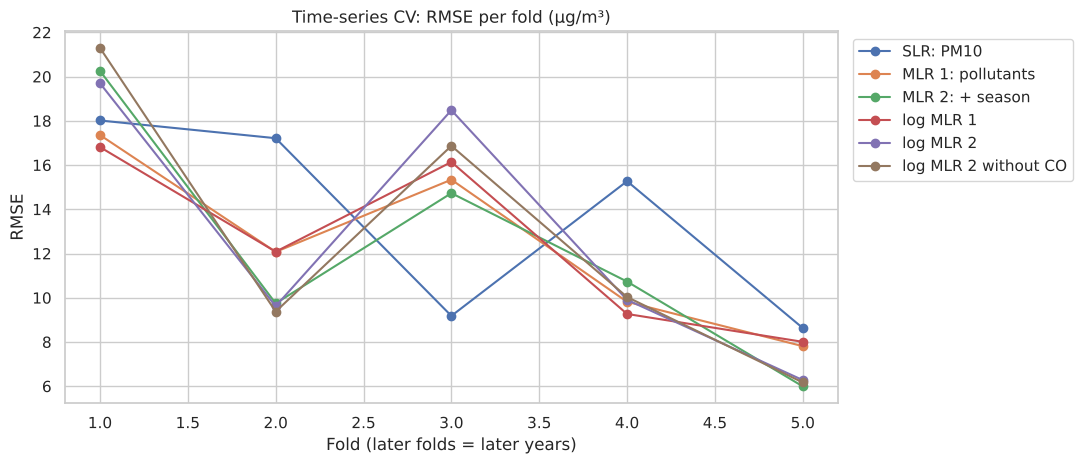

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
pivot = ts_cv.pivot(index="fold", columns="model", values="RMSE")[list(candidates)]
pivot.plot(marker="o", ax=ax)
ax.set(title="Time-series CV: RMSE per fold (µg/m³)", xlabel="Fold (later folds = later years)", ylabel="RMSE")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "17_cv_rmse_by_fold.png", dpi=150); plt.show()

**Reading the CV results:**

- **The period tested matters more than the model.** Fold RMSE ranges from about 6 to 20 µg/m³, while the multi-predictor models differ by under 0.5 on average. Fold 1 (winter 2016-17) and fold 3 (late 2017-2018) contain the spikiest days; fold 5 (2019) is calm.
- All multi-predictor models beat the single-predictor SLR. Among them, the differences are well within one fold standard deviation, so CV alone cannot separate them.
- **Random CV was not more optimistic here.** Its test folds are spread over all years, including the spiky 2016-17 period, while the later time-series folds are calmer. The time-series result is still the honest one, because it never uses future days to predict the past.
- CV errors (≈ 12) are higher than the hold-out test error from notebook 04 (≈ 8). The 2019-20 test period is calmer than the 2016-18 years inside the CV folds.

## 4. Coefficient stability across CV folds

If an estimator is stable, its coefficient should not change much when it is re-estimated on different stretches of time.

In [9]:
coef_rows = []
for fold, (tr_idx, _) in enumerate(TS.split(train)):
    m = smf.ols("np.log(PM25) ~ " + rhs(PREDICTORS + [SEASON]), data=train.iloc[tr_idx]).fit()
    coef_rows.append(m.params.rename(f"fold {fold + 1}"))
coef_rows.append(full.params.rename("all training data"))
fold_coefs = pd.DataFrame(coef_rows).T.loc[PREDICTORS]
fold_coefs["CV of coefficient (sd/|mean|)"] = fold_coefs.iloc[:, :5].std(axis=1) / fold_coefs.iloc[:, :5].mean(axis=1).abs()
fold_coefs["sign stable?"] = (np.sign(fold_coefs.iloc[:, :5]).nunique(axis=1) == 1)
fold_coefs.to_csv(TAB / "coefficient_stability_folds.csv")
fold_coefs

,fold 1,fold 2,fold 3,fold 4,fold 5,all training data,CV of coefficient (sd/|mean|),sign stable?
PM10,0.0028,0.0032,0.0033,0.0036,0.0039,0.0042,0.1253,True
NO,-0.0083,-0.0123,-0.0123,-0.0087,-0.0081,-0.0076,0.2171,True
NO2,0.0060,0.0043,0.0029,0.0045,0.0046,0.0047,0.2430,True
NOx,0.0041,0.0102,0.0110,0.0080,0.0078,0.0080,0.3246,True
NH3,0.0065,0.0061,0.0086,0.0036,0.0038,0.0043,0.3572,True
CO,-0.0664,-0.0530,-0.0457,-0.0295,-0.0319,-0.0283,0.3374,True
SO2,0.0167,0.0245,0.0265,0.0224,0.0194,0.0181,0.1781,True
O3,0.0024,0.0037,0.0044,0.0032,0.0040,0.0039,0.2165,True


**Reading the table:** every pollutant keeps the same sign in all 5 folds, so the direction of each effect is stable. The sizes vary more: PM10's coefficient grows steadily from fold 1 to fold 5, which suggests its link with PM2.5 strengthened over time, while NH3 and NOx move the most (coefficient of variation ≈ 0.3-0.36).

# Part C: Bootstrap distribution of the estimators

The bootstrap re-samples the data many times, refits the model each time, and collects the coefficients. Their spread is the **sampling distribution** of each estimator, with no normality assumption.

- **Case (i.i.d.) bootstrap:** resamples individual days. It assumes days are independent, which notebook 04 showed is false.
- **Moving-block bootstrap:** resamples blocks of 14 consecutive days, keeping the day-to-day dependence inside each block. This is the correct method for autocorrelated data.

Model: **log MLR 2** (all 8 pollutants + season), B = 2000 resamples each.

In [10]:
y_all = np.log(train["PM25"].values)
X_all = full.model.exog                      # same design matrix as the full model
names = full.params.index
B, BLOCK = 2000, 14

def ols_beta(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def case_bootstrap():
    idx = rng.integers(0, n, size=(B, n))
    return np.array([ols_beta(X_all[i], y_all[i]) for i in idx])

def block_bootstrap():
    n_blocks = int(np.ceil(n / BLOCK))
    starts = rng.integers(0, n - BLOCK + 1, size=(B, n_blocks))
    out = []
    for s in starts:
        i = (s[:, None] + np.arange(BLOCK)).ravel()[:n]
        out.append(ols_beta(X_all[i], y_all[i]))
    return np.array(out)

boot_case = pd.DataFrame(case_bootstrap(), columns=names)
boot_block = pd.DataFrame(block_bootstrap(), columns=names)
print("Bootstrap done:", boot_case.shape, boot_block.shape)

Bootstrap done: (2000, 12) (2000, 12)


In [11]:
ci = full.conf_int()
boot_table = pd.DataFrame({
    "OLS estimate": full.params,
    "OLS SE": full.bse,
    "Case-boot SE": boot_case.std(),
    "Block-boot SE": boot_block.std(),
    "Block-boot bias": boot_block.mean() - full.params,
    "OLS 95% CI low": ci[0], "OLS 95% CI high": ci[1],
    "Block 95% CI low": boot_block.quantile(0.025), "Block 95% CI high": boot_block.quantile(0.975),
})
boot_table["Block CI excludes 0?"] = (boot_table["Block 95% CI low"] > 0) | (boot_table["Block 95% CI high"] < 0)
boot_table["SE ratio block/OLS"] = boot_table["Block-boot SE"] / boot_table["OLS SE"]
boot_table.to_csv(TAB / "bootstrap_coefficients.csv")
boot_table

,OLS estimate,OLS SE,Case-boot SE,Block-boot SE,Block-boot bias,OLS 95% CI low,OLS 95% CI high,Block 95% CI low,Block 95% CI high,Block CI excludes 0?,SE ratio block/OLS
Intercept,2.7137,0.0604,0.0640,0.1179,-0.0039,2.5952,2.8322,2.4731,2.9359,True,1.9515
"C(Season, Treatment('Winter'))[T.Monsoon]",-0.3629,0.0324,0.0356,0.0681,0.0003,-0.4264,-0.2994,-0.4941,-0.2355,True,2.1045
"C(Season, Treatment('Winter'))[T.Post-monsoon]",-0.0422,0.0321,0.0331,0.0671,-0.0081,-0.1051,0.0208,-0.1826,0.0761,False,2.0926
"C(Season, Treatment('Winter'))[T.Summer]",-0.0306,0.0301,0.0276,0.0508,-0.0004,-0.0896,0.0285,-0.1274,0.0684,False,1.6893
PM10,0.0042,0.0003,0.0004,0.0006,-0.0000,0.0036,0.0047,0.0030,0.0054,True,2.2732
NO,-0.0076,0.0018,0.0019,0.0028,-0.0007,-0.0111,-0.0041,-0.0138,-0.0030,True,1.5727
NO2,0.0047,0.0011,0.0012,0.0018,0.0000,0.0025,0.0070,0.0011,0.0084,True,1.5753
NOx,0.0080,0.0007,0.0008,0.0013,0.0002,0.0065,0.0094,0.0058,0.0106,True,1.7668
NH3,0.0043,0.0008,0.0010,0.0024,0.0002,0.0028,0.0058,0.0006,0.0099,True,3.2230
CO,-0.0283,0.0104,0.0132,0.0191,0.0033,-0.0487,-0.0078,-0.0551,0.0168,False,1.8319


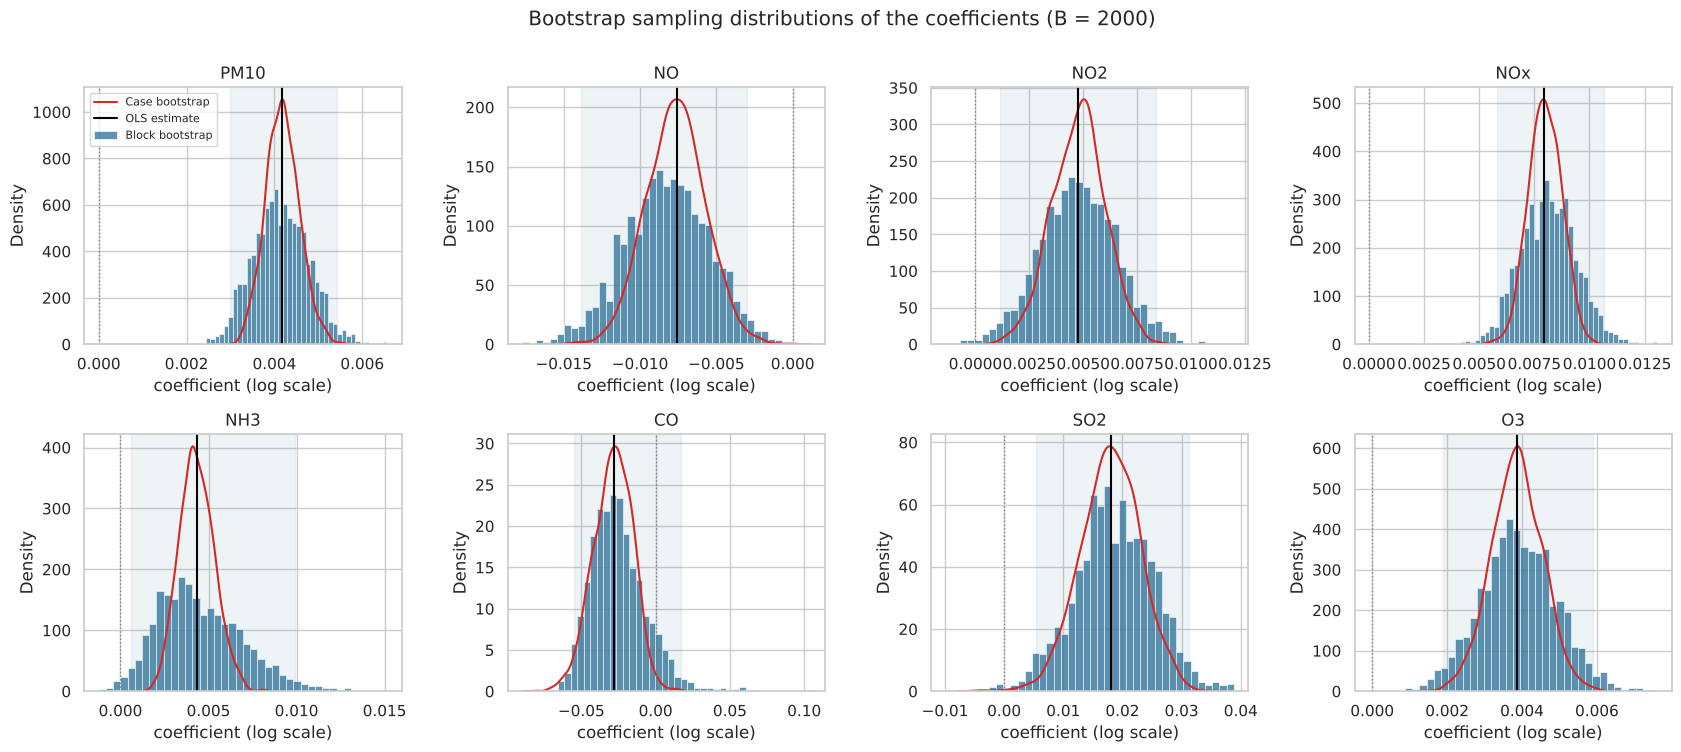

In [12]:
show = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, c in zip(axes.ravel(), show):
    sns.histplot(boot_block[c], ax=ax, color="#2a6f97", stat="density", bins=40, label="Block bootstrap")
    sns.kdeplot(boot_case[c], ax=ax, color="#d62828", lw=1.5, label="Case bootstrap")
    ax.axvline(full.params[c], color="black", lw=1.5, label="OLS estimate")
    ax.axvline(0, color="grey", ls=":", lw=1)
    lo, hi = boot_block[c].quantile([0.025, 0.975])
    ax.axvspan(lo, hi, color="#2a6f97", alpha=0.08)
    ax.set_title(c); ax.set_xlabel("coefficient (log scale)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Bootstrap sampling distributions of the coefficients (B = 2000)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "18_bootstrap_distributions.png", dpi=150); plt.show()

## 5. Is the sampling distribution normal?

OLS confidence intervals assume each estimator is normally distributed. A Q-Q check on the block-bootstrap draws tests that directly.

In [13]:
from scipy import stats
normality = pd.DataFrame({
    "skew": boot_block[show].skew(),
    "excess kurtosis": boot_block[show].kurt(),
    "Shapiro p (500 draws)": [stats.shapiro(boot_block[c].sample(500, random_state=1))[1] for c in show],
})
normality.to_csv(TAB / "bootstrap_normality.csv")
normality

,skew,excess kurtosis,Shapiro p (500 draws)
PM10,0.1907,-0.0451,0.4504
NO,-0.0926,-0.0559,0.9285
NO2,0.0373,0.2246,0.3609
NOx,0.1020,0.0883,0.6807
NH3,0.5797,0.2290,0.0000
CO,1.0800,3.0986,0.0000
SO2,-0.1219,0.1562,0.2119
O3,0.0252,0.0865,0.2529


**Reading the bootstrap results:**

- **Case bootstrap SEs ≈ the OLS/HC3 SEs**, because both assume independent days.
- **Block bootstrap SEs are 1.4 to 3.2 times the OLS SEs.** Ignoring the day-to-day dependence makes OLS look far more precise than it is. This agrees with the Newey-West result in notebook 04.
- **Bias is negligible:** the bootstrap mean is almost identical to the OLS estimate for every coefficient, so OLS is (close to) unbiased here.
- Even with the wider block intervals, **PM10, NOx, NO, NO2, NH3, SO2, O3 and Monsoon stay clearly away from 0**. **CO, Summer and Post-monsoon** do not: their block 95% intervals include 0.
- Most sampling distributions are close to normal (Shapiro p > 0.05), so normal-theory intervals are reasonable for them. CO and NH3 are right-skewed, so their percentile bootstrap intervals are the ones to trust.

## 6. Final regression model

The selection combines all three lines of evidence: information criteria (Part A), out-of-sample error (Part B) and estimator stability (Part C).

In [14]:
final_choice = pd.DataFrame({
    "criterion": ["Lowest AIC", "Lowest BIC", "Lowest Cp", "Best TS-CV RMSE", "Best TS-CV MAE"],
    "winner": [best.loc["Lowest AIC", "predictors"], best.loc["Lowest BIC", "predictors"], best.loc["Lowest Cp", "predictors"],
               cv_summary["TS-CV RMSE (mean)"].idxmin(), cv_summary["TS-CV MAE (mean)"].idxmin()],
})
final_choice.to_csv(TAB / "phase1_model_choice.csv", index=False)
final_choice

,criterion,winner
0,Lowest AIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season"
1,Lowest BIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season"
2,Lowest Cp,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season"
3,Best TS-CV RMSE,MLR 2: + season
4,Best TS-CV MAE,log MLR 2


**Selected Phase 1 model: log MLR 2**, i.e. log(PM2.5) on all 8 pollutants + Season.

1. It wins AIC, BIC and Mallow's $C_p$ outright.
2. It has the lowest time-series CV MAE; its CV RMSE is within 0.5 µg/m³ of the best, far inside the fold-to-fold spread.
3. Its residuals satisfy the linearity assumption and are close to symmetric (notebook 04), unlike the untransformed models.
4. Its coefficient signs are stable across all CV folds, and the block bootstrap confirms which effects are reliable.

**Caveat:** CO and the Summer/Post-monsoon dummies are kept for prediction, but their block-bootstrap intervals include 0, so they are not interpreted as reliable effects. This matches the HAC and GLSAR results in notebook 04.